In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import gamma


### 1D Profiles


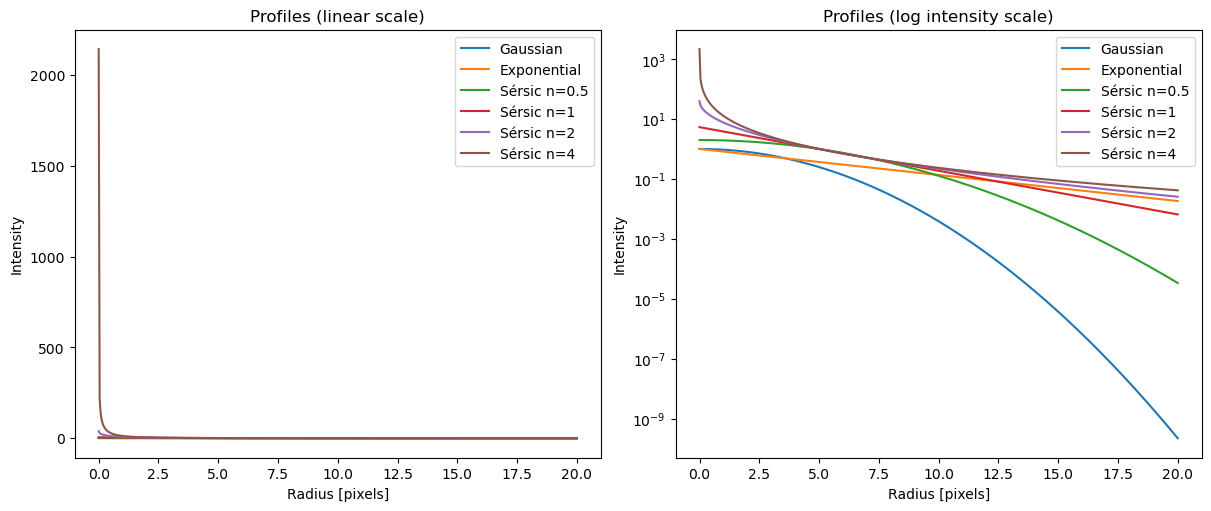

In [2]:
def gaussian_profile(r, I0=1.0, sigma=3.0):
    return I0 * np.exp(-0.5 * (r / sigma)**2)

def exponential_profile(r, I0=1.0, h=5.0):
    return I0 * np.exp(-r / h)

def b_n(n):
    # Good approximation for Sérsic bn
    return 2*n - 1/3 + 0.009876/n

def sersic_profile(r, Ie=1.0, Re=5.0, n=1.0):
    bn = b_n(n)
    return Ie * np.exp(-bn * ((r / Re)**(1/n) - 1))

r = np.linspace(0, 20, 500)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# Linear scale
axes[0].plot(r, gaussian_profile(r, I0=1, sigma=3), label='Gaussian')
axes[0].plot(r, exponential_profile(r, I0=1, h=5), label='Exponential')
axes[0].plot(r, sersic_profile(r, Ie=1, Re=5, n=0.5), label='Sérsic n=0.5')
axes[0].plot(r, sersic_profile(r, Ie=1, Re=5, n=1), label='Sérsic n=1')
axes[0].plot(r, sersic_profile(r, Ie=1, Re=5, n=2), label='Sérsic n=2')
axes[0].plot(r, sersic_profile(r, Ie=1, Re=5, n=4), label='Sérsic n=4')
axes[0].set_title("Profiles (linear scale)")
axes[0].set_xlabel("Radius [pixels]")
axes[0].set_ylabel("Intensity")
axes[0].legend()

# Log scale
axes[1].plot(r, gaussian_profile(r, I0=1, sigma=3), label='Gaussian')
axes[1].plot(r, exponential_profile(r, I0=1, h=5), label='Exponential')
axes[1].plot(r, sersic_profile(r, Ie=1, Re=5, n=0.5), label='Sérsic n=0.5')
axes[1].plot(r, sersic_profile(r, Ie=1, Re=5, n=1), label='Sérsic n=1')
axes[1].plot(r, sersic_profile(r, Ie=1, Re=5, n=2), label='Sérsic n=2')
axes[1].plot(r, sersic_profile(r, Ie=1, Re=5, n=4), label='Sérsic n=4')
axes[1].set_yscale('log')
axes[1].set_title("Profiles (log intensity scale)")
axes[1].set_xlabel("Radius [pixels]")
axes[1].set_ylabel("Intensity")
axes[1].legend()

plt.show()

### 2D Profiles

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, AsinhStretch


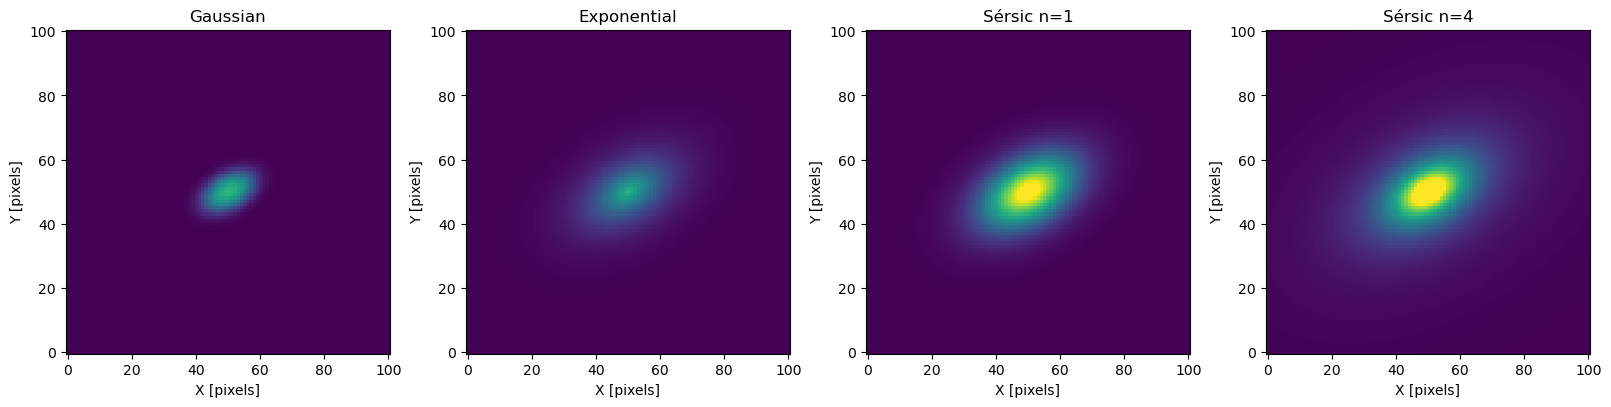

In [6]:
#grid
ny, nx = 101, 101
y, x = np.mgrid[0:ny, 0:nx]

xc, yc = 50, 50



def elliptical_radius(x, y, x0, y0, q=1.0, pa_deg=0.0):
    theta = np.deg2rad(pa_deg)
    xp = (x - x0)*np.cos(theta) + (y - y0)*np.sin(theta)
    yp = -(x - x0)*np.sin(theta) + (y - y0)*np.cos(theta)
    return np.sqrt(xp**2 + (yp / q)**2)

# -----------------------------
# 2D profiles
# -----------------------------

def gaussian_2d(x, y, x0, y0, I0=1.0, sigma=5.0, q=1.0, pa_deg=0.0):
    R = elliptical_radius(x, y, x0, y0, q=q, pa_deg=pa_deg)
    return I0 * np.exp(-0.5 * (R / sigma)**2)

def exponential_2d(x, y, x0, y0, I0=1.0, h=8.0, q=1.0, pa_deg=0.0):
    R = elliptical_radius(x, y, x0, y0, q=q, pa_deg=pa_deg)
    return I0 * np.exp(-R / h)

def b_n(n):
    return 2*n - 1/3 + 0.009876/n

def sersic_2d(x, y, x0, y0, Ie=1.0, Re=10.0, n=2.0, q=1.0, pa_deg=0.0):
    R = elliptical_radius(x, y, x0, y0, q=q, pa_deg=pa_deg)
    bn = b_n(n)
    return Ie * np.exp(-bn * ((R / Re)**(1/n) - 1))

# -----------------------------
# Models
# -----------------------------

img_gauss = gaussian_2d(x, y, xc, yc, I0=1, sigma=5, q=0.6, pa_deg=30)
img_exp   = exponential_2d(x, y, xc, yc, I0=1, h=8, q=0.6, pa_deg=30)
img_s1    = sersic_2d(x, y, xc, yc, Ie=1, Re=10, n=1, q=0.6, pa_deg=30)
img_s4    = sersic_2d(x, y, xc, yc, Ie=1, Re=10, n=4, q=0.6, pa_deg=30)

images = [img_gauss, img_exp, img_s1, img_s4]
titles = ["Gaussian", "Exponential", "Sérsic n=1", "Sérsic n=4"]

# Shared display scale
stack = np.concatenate([img.ravel() for img in images])
vmin, vmax = np.percentile(stack, [1, 99.8])
norm = ImageNormalize(vmin=vmin, vmax=vmax, stretch=AsinhStretch())

# Plot
fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

for ax, img, title in zip(axes, images, titles):
    im = ax.imshow(img, origin='lower', norm=norm)
    ax.set_title(title)
    ax.set_xlabel("X [pixels]")
    ax.set_ylabel("Y [pixels]")

plt.show()

In [ ]:
## change gaussian(sigma), exponential(h), sersic(n)

### Practice with PSF convolution

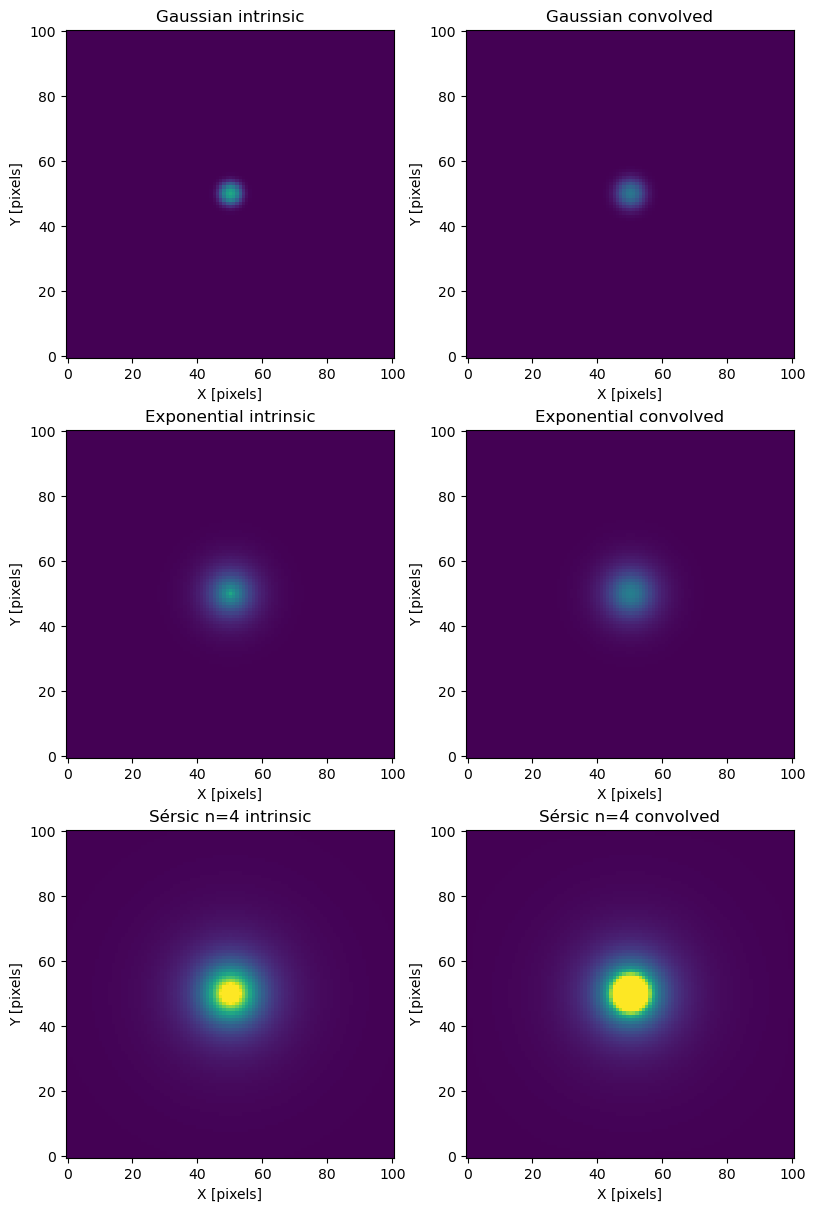

In [ ]:
from scipy.signal import fftconvolve

# -----------------------------
# Make a Gaussian PSF
# -----------------------------

def make_psf(n=41, sigma=2.0):
    y, x = np.mgrid[0:n, 0:n]
    xc = yc = n // 2
    psf = np.exp(-0.5 * (((x-xc)**2 + (y-yc)**2) / sigma**2))
    psf /= psf.sum()
    return psf

psf = make_psf(n=41, sigma=2.0)

# Example intrinsic models
intrinsic_gauss = gaussian_2d(x, y, xc, yc, I0=1, sigma=2, q=1.0, pa_deg=0)
intrinsic_exp   = exponential_2d(x, y, xc, yc, I0=1, h=4, q=1.0, pa_deg=0)
intrinsic_s4    = sersic_2d(x, y, xc, yc, Ie=1, Re=6, n=4, q=1.0, pa_deg=0)

conv_gauss = fftconvolve(intrinsic_gauss, psf, mode='same')
conv_exp   = fftconvolve(intrinsic_exp, psf, mode='same')
conv_s4    = fftconvolve(intrinsic_s4, psf, mode='same')

images = [
    intrinsic_gauss, conv_gauss,
    intrinsic_exp,   conv_exp,
    intrinsic_s4,    conv_s4
]

titles = [
    "Gaussian intrinsic", "Gaussian convolved",
    "Exponential intrinsic", "Exponential convolved",
    "Sérsic n=4 intrinsic", "Sérsic n=4 convolved"
]

stack = np.concatenate([img.ravel() for img in images])
vmin, vmax = np.percentile(stack, [1, 99.8])
norm = ImageNormalize(vmin=vmin, vmax=vmax, stretch=AsinhStretch())

fig, axes = plt.subplots(3, 2, figsize=(8, 12), constrained_layout=True)

for ax, img, title in zip(axes.ravel(), images, titles):
    ax.imshow(img, origin='lower', norm=norm)
    ax.set_title(title)
    ax.set_xlabel("X [pixels]")
    ax.set_ylabel("Y [pixels]")

plt.show()